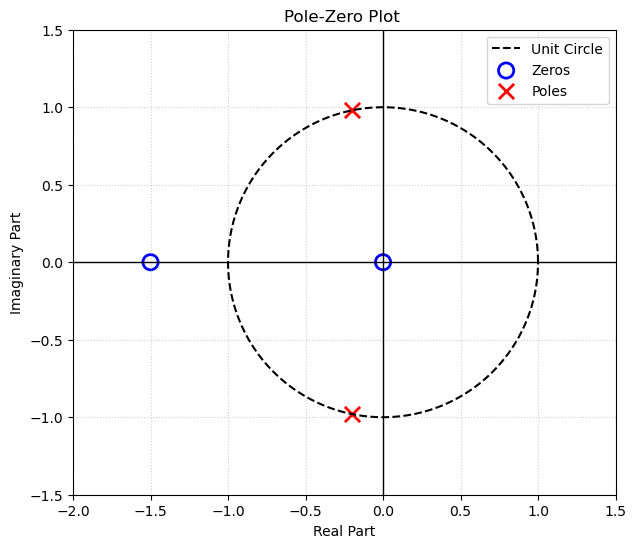

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

num = [2, 3, 0]
den = [1, 0.4, 1]

# Roots calculation
zeros, poles, k = signal.tf2zpk(num, den)

fig, ax = plt.subplots(figsize=(7, 7))

# Plotting the Unit Circle
theta = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(theta), np.sin(theta), color='black', linestyle='--', linewidth=1.5, label='Unit Circle')

# Plotting Poles (x) and Zeros (o)
ax.scatter(np.real(zeros), np.imag(zeros), s=120, marker='o', facecolors='none', edgecolors='blue', linewidth=2, label='Zeros')
ax.scatter(np.real(poles), np.imag(poles), s=120, marker='x', color='red', linewidth=2, label='Poles')

# Appearance and axis settings
ax.axhline(0, color='black', lw=1)
ax.axvline(0, color='black', lw=1)
ax.set_xlim([-2.0, 1.5])
ax.set_ylim([-1.5, 1.5])
ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.6)

plt.title(r'Pole-Zero Plot ', fontsize=12)
plt.xlabel('Real Part')
plt.ylabel('Imaginary Part')
plt.legend()
plt.show()


C:\Users\karam\anaconda3\envs\pr\Lib\site-packages\control\pzmap.py:327: FutureWarning: pole_zero_plot() return value of poles, zeros is deprecated; use pole_zero_map()
  warnings.warn(


Poles: [0.2+0.4j 0.2-0.4j]
Zeros: [-0.25+0.4330127j -0.25-0.4330127j]


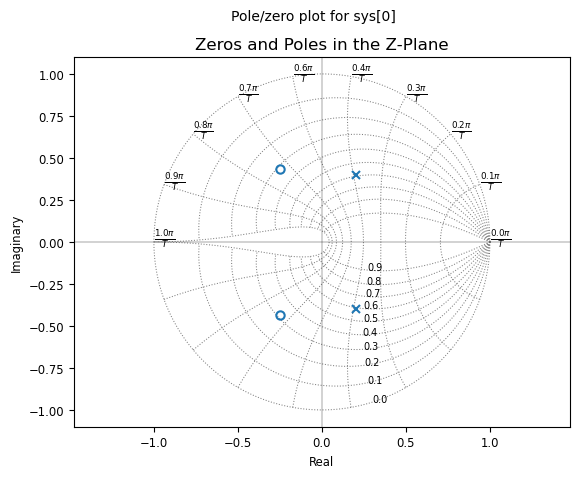

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import control as ctrl

# Define the transfer function
numerator = [1, 0.5, 0.25]
denominator = [1, -0.4, 0.2]
system = ctrl.TransferFunction(numerator, denominator, True)

# Plot the zeros and poles. pzmap cannot compute the gain 
poles, zeros = ctrl.pzmap(system, plot=True, grid=True)

# Print the poles and zeros
print("Poles:", poles)
print("Zeros:", zeros)

plt.title('Zeros and Poles in the Z-Plane')
plt.show()


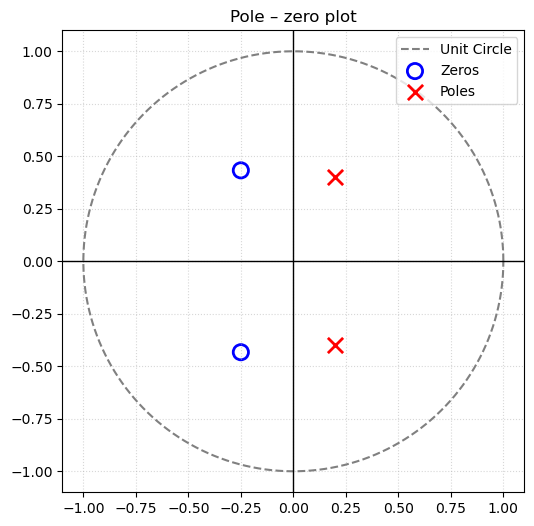

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Coefficients 
num = [1, 0.5, 0.25]
den = [1, -0.4, 0.2]

# Pole/Zero calculation
zeros, poles, k = signal.tf2zpk(num, den)
plt.figure(figsize=(6, 6), facecolor='white')

# Plotting the Unit Circle
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--', label='Unit Circle')

# Plotting the points
plt.scatter(np.real(zeros), np.imag(zeros), s=120, marker='o', facecolors='none', edgecolors='blue', linewidth=2, label='Zeros')
plt.scatter(np.real(poles), np.imag(poles), s=120, marker='x', color='red', linewidth=2, label='Poles')
plt.axhline(0, color='black', lw=1)
plt.axvline(0, color='black', lw=1)

plt.xlim([-1.1, 1.1])
plt.ylim([-1.1, 1.1])
plt.gca().set_aspect('equal')
plt.grid(True, linestyle=':', alpha=0.5)
plt.title(r'Pole – zero plot', fontsize=12)
plt.legend(loc='upper right', frameon=True).set_zorder(5)

plt.show()



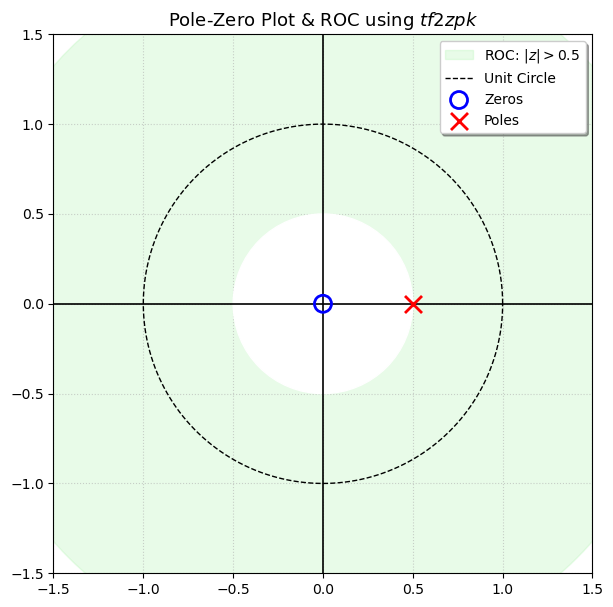

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

num = [1, 0]
den = [1, -0.5]

# Pole and Zero calculation
zeros, poles, gain = signal.tf2zpk(num, den)
fig, ax = plt.subplots(figsize=(7, 7), facecolor='white')

# ROC Plotting - Causal System
# Plotting the ROC background
roc_area = plt.Circle((0, 0), 2.0, color='lightgreen', alpha=0.2, label='ROC: $|z| > 0.5$')
ax.add_artist(roc_area)
# Central “hole” up to the pole
white_center = plt.Circle((0, 0), np.max(np.abs(poles)), color='white', zorder=2)
ax.add_artist(white_center)
# Plotting the Unit Circle
theta = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(theta), np.sin(theta), color='black', linestyle='--', linewidth=1, label='Unit Circle')

# Plotting Poles and Zeros
ax.scatter(np.real(zeros), np.imag(zeros), s=150, marker='o', facecolors='none', 
           edgecolors='blue', linewidth=2, label='Zeros', zorder=3)
ax.scatter(np.real(poles), np.imag(poles), s=150, marker='x', color='red', 
           linewidth=2, label='Poles', zorder=3)

# Axis Settings & Legend
ax.axhline(0, color='black', lw=1.2)
ax.axvline(0, color='black', lw=1.2)
ax.set_xlim([-1.5, 1.5])
ax.set_ylim([-1.5, 1.5])
ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.6)
# Legend Top Right
ax.legend(loc='upper right', frameon=True, shadow=True)
plt.title(r'Pole-Zero Plot & ROC using $tf2zpk$', fontsize=13)
plt.show()


In [8]:
def plot_z_plane(zeros, poles, show_roc=1):
    fig, ax = plt.subplots(figsize=(7, 7), facecolor='white')

    # Maximum pole for ROC calculation and axis limits
    max_p = np.max(np.abs(poles)) if len(poles) > 0 else 0
    
    # ROC Plotting (Only if show_roc == 1)
    if show_roc == 1:
        roc_limit = max(2.5, max_p + 1.0)
        # Πράσινη περιοχή (πίσω-πίσω)
        roc_area = plt.Circle((0, 0), roc_limit, color='lightgreen', alpha=0.2, label=f'ROC: $|z| > {max_p:.2f}$', zorder=1)
        ax.add_artist(roc_area)
        # White "hole" (on top of ROC, below the X markers)
        white_center = plt.Circle((0, 0), max_p, color='white', 
        zorder=2)
        ax.add_artist(white_center)

    # Unit Circle
    theta = np.linspace(0, 2*np.pi, 200)
    ax.plot(np.cos(theta), np.sin(theta), color='black', linestyle='--', 
            linewidth=1, label='Unit Circle', zorder=3)

    # Poles and Zeros 
    ax.scatter(np.real(zeros), np.imag(zeros), s=150, marker='o', 
               facecolors='none', edgecolors='blue', linewidth=2, 
               label='Zeros', zorder=4)
    ax.scatter(np.real(poles), np.imag(poles), s=150, marker='x', 
               color='red', linewidth=2, label='Poles', zorder=4)

    # Automatic axis adjustment
    all_coords = np.concatenate(([1.2], np.abs(poles), np.abs(zeros)))
    limit = np.max(all_coords) + 0.3
    ax.set_xlim([-limit, limit])
    ax.set_ylim([-limit, limit])
    
    ax.axhline(0, color='black', lw=1, zorder=3)
    ax.axvline(0, color='black', lw=1, zorder=3)
    ax.set_aspect('equal')
    ax.legend(loc='upper right', frameon=True).set_zorder(5)
    ax.grid(True, linestyle=':', alpha=0.5, zorder=0)
    plt.show()


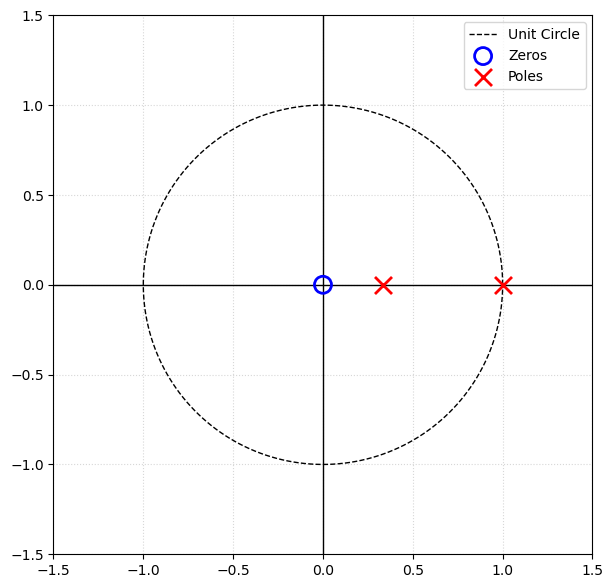

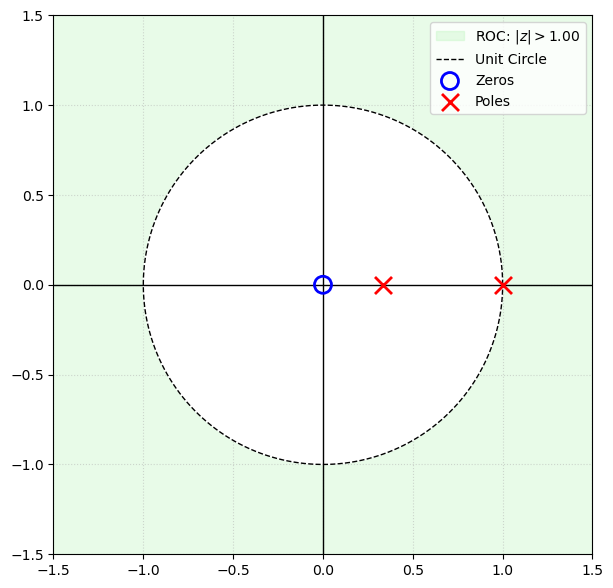

In [11]:
import scipy
b = [0, 1, 0] 
a = [3, -4, 1]
z, p, c = scipy.signal.tf2zpk(b,a)
plot_z_plane(z,p,show_roc=0)
plot_z_plane(z,p,show_roc=1)


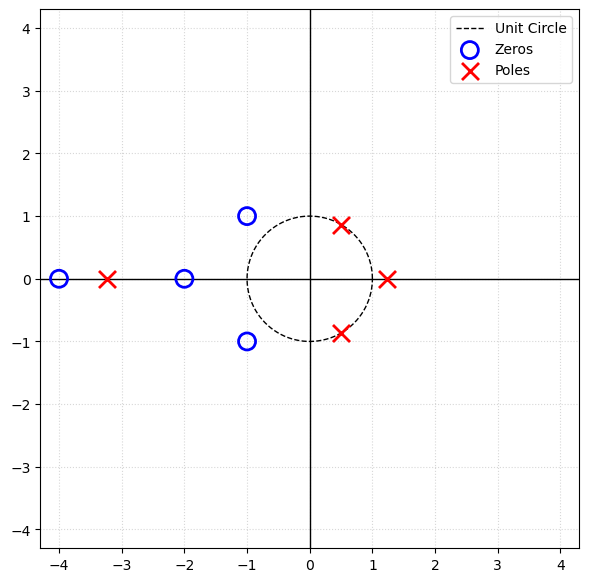

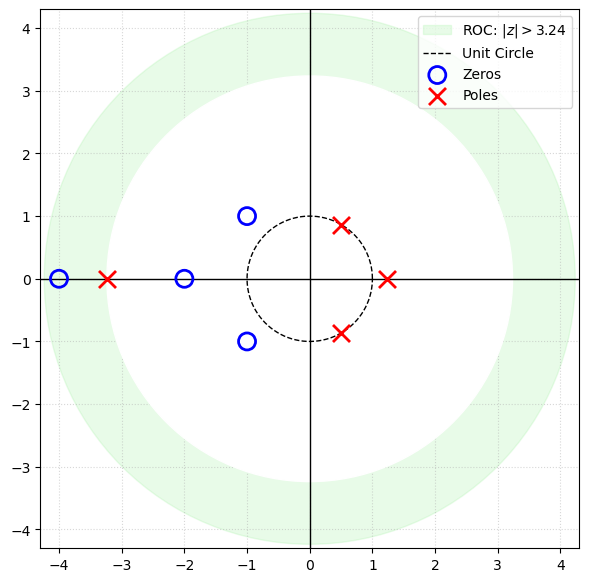

In [13]:
b = [2, 16, 44, 56, 32] 
a = [3, 3, -15, 18, -12]

z, p, c = scipy.signal.tf2zpk(b,a)
plot_z_plane(z,p, show_roc=0)
plot_z_plane(z,p, show_roc=1)
